# EN4554 Assignment 2: CNNs
**Name:** YASHODHARA M.H.K.

**Index Number:** 220735E

**GitHub Profile:** https://github.com/HansaniKaumadi/EN4554-Assignment-2-on-CNNs/tree/main


**Acknowledgment of AI Tools:**
I used AI tools (Claude) for coding assistance and debugging during this assignment. I fully understand the code implemented in this notebook.

In [1]:
# # Setup and Imports
# import torch
# import torch.nn as nn
# import torch.optim as optim
# import torchvision
# import torchvision.transforms as transforms
# from torch.utils.data import DataLoader, random_split, Subset
# import numpy as np
# import matplotlib.pyplot as plt
# import copy
# import itertools

# # Fix random seeds
# torch.manual_seed(42)
# np.random.seed(42)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # CIFAR-10 Setup (45k train, 5k val)
# # First pass to get training statistics
# temp_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
# temp_loader = DataLoader(temp_train, batch_size=len(temp_train))
# data = next(iter(temp_loader))[0]
# mean, std = data.mean(dim=[0, 2, 3]), data.std(dim=[0, 2, 3])

# transform = transforms.Compose([
#     transforms.ToTensor(),
#     transforms.Normalize(mean, std)
# ])

# dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
# train_set, val_set = random_split(dataset, [45000, 5000])

# train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
# val_loader = DataLoader(val_set, batch_size=128, shuffle=False)

100%|██████████| 170M/170M [49:15<00:00, 57.7kB/s]


In [ ]:
# Setup and Imports
import copy, random
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, random_split, Dataset
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_TRAIN, N_VAL = 45000, 5000
NUM_WORKERS = 2

# Base dataset keeps RAW PIL images (transform=None). Every split gets its own transform below,
# so training/validation/test inputs are always normalised in the same way.
base = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=None)
train_set, val_set = random_split(base, [N_TRAIN, N_VAL], generator=torch.Generator().manual_seed(SEED))

# Per-channel statistics from the TRAINING split only (45k images, not the validation 5k)
imgs = base.data[train_set.indices]                                   # uint8, (N, 32, 32, 3)
mean = [float(imgs[..., c].mean() / 255.) for c in range(3)]
std  = [float(imgs[..., c].std()  / 255.) for c in range(3)]
del imgs
print('train-split mean:', np.round(mean, 4), '| std:', np.round(std, 4))

class Cutout:
    """Cutout on an already-normalised tensor: a length x length square is set to 0 (= the mean pixel)."""
    def __init__(self, length=16): self.length = length
    def __call__(self, img):
        _, h, w = img.shape
        y, x = int(torch.randint(h, (1,))), int(torch.randint(w, (1,)))
        y1, y2 = max(0, y - self.length // 2), min(h, y + self.length // 2)
        x1, x2 = max(0, x - self.length // 2), min(w, x + self.length // 2)
        img = img.clone(); img[:, y1:y2, x1:x2] = 0.
        return img

normalize   = transforms.Normalize(mean, std)
plain_tf    = transforms.Compose([transforms.ToTensor(), normalize])                       # no augmentation
flipcrop_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                                  transforms.ToTensor(), normalize])
cutout_tf   = transforms.Compose([transforms.ToTensor(), normalize, Cutout(16)])
full_aug_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                                  transforms.ToTensor(), normalize, Cutout(16)])
transform = plain_tf          # name kept for the test-set cell

class TransformedSubset(Dataset):
    """Applies a transform to the items of a Subset. (Setting .transform on a Subset does nothing!)"""
    def __init__(self, subset, tf): self.subset, self.tf = subset, tf
    def __len__(self): return len(self.subset)
    def __getitem__(self, i):
        img, y = self.subset[i]
        return self.tf(img), y

mk = lambda ds, tf, shuffle: DataLoader(TransformedSubset(ds, tf), batch_size=128, shuffle=shuffle, num_workers=NUM_WORKERS)
train_loader     = mk(train_set, plain_tf,    True)     # normalised, NO augmentation (used by Tasks 1-3b)
train_loader_aug = mk(train_set, full_aug_tf, True)     # flip+crop+cutout (used by Task 4)
val_loader       = mk(val_set,   plain_tf,    False)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct = total = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        correct += (model(xb).argmax(1) == yb).sum().item(); total += yb.size(0)
    return correct / total

print(f'train {len(train_set)} | val {len(val_set)} | device {device}')

# Task 1: Backpropagation

In [17]:
# (a) Explicit forward/backward
class Linear:
    def __init__(self, in_features, out_features):
        self.weight = torch.randn(in_features, out_features) * np.sqrt(2. / in_features)
        self.bias = torch.zeros(out_features)
        self.grad_weight = None
        self.grad_bias = None
        self.x = None

    def forward(self, x):
        self.x = x
        return x @ self.weight + self.bias

    def backward(self, grad_output):
        self.grad_weight = self.x.T @ grad_output
        self.grad_bias = grad_output.sum(dim=0)
        return grad_output @ self.weight.T

class ReLU:
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return torch.maximum(x, torch.zeros_like(x))

    def backward(self, grad_output):
        return grad_output * (self.x > 0).float()

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        self.targets = targets
        exp_logits = torch.exp(logits - logits.max(dim=1, keepdim=True).values)
        self.probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        batch_size = logits.shape[0]
        loss = -torch.log(self.probs[range(batch_size), targets] + 1e-9).mean()
        return loss

    def backward(self):
        batch_size = self.probs.shape[0]
        grad_input = self.probs.clone()
        grad_input[range(batch_size), self.targets] -= 1
        return grad_input / batch_size

In [18]:
# (b) Gradient verification of the assembled MLP: explicit backward vs autograd vs centred finite differences
# float64 is used: in float32 the finite-difference error is dominated by round-off, not by the method.
def build_check_mlp(dims):
    layers = []
    for i in range(len(dims) - 1):
        lin = Linear(dims[i], dims[i + 1])
        lin.weight = lin.weight.double()
        lin.bias = (torch.randn(dims[i + 1]) * 0.1).double()      # non-zero biases so that db is really tested
        layers.append(lin)
        if i < len(dims) - 2: layers.append(ReLU())
    return layers

def mlp_forward(layers, x):
    for l in layers: x = l.forward(x)
    return x

def verify_gradients(h=1e-6):
    torch.manual_seed(42)
    layers = build_check_mlp([12, 16, 16, 5])                      # Linear-ReLU-Linear-ReLU-Linear
    lins = [l for l in layers if isinstance(l, Linear)]
    x = torch.randn(8, 12, dtype=torch.float64); y = torch.randint(0, 5, (8,))
    ce = SoftmaxCrossEntropy()

    # 1. explicit backward
    ce.forward(mlp_forward(layers, x), y)
    g = ce.backward()
    for l in reversed(layers): g = l.backward(g)
    custom = {}
    for k, l in enumerate(lins, 1):
        custom[f'W{k}'], custom[f'b{k}'] = l.grad_weight.clone(), l.grad_bias.clone()

    # 2. autograd on copies of the same parameters
    P = {}
    for k, l in enumerate(lins, 1):
        P[f'W{k}'], P[f'b{k}'] = l.weight.clone().requires_grad_(True), l.bias.clone().requires_grad_(True)
    hid = x
    for k in range(1, len(lins) + 1):
        hid = hid @ P[f'W{k}'] + P[f'b{k}']
        if k < len(lins): hid = torch.relu(hid)
    nn.functional.cross_entropy(hid, y).backward()

    # 3. centred finite differences: (L(w+h) - L(w-h)) / 2h for EVERY entry of every parameter
    live = {}
    for k, l in enumerate(lins, 1): live[f'W{k}'], live[f'b{k}'] = l.weight, l.bias
    def loss_now(): return ce.forward(mlp_forward(layers, x), y).item()
    fd = {}
    for name, p in live.items():
        grad = torch.zeros_like(p); pf, gf = p.view(-1), grad.view(-1)
        for i in range(pf.numel()):
            old = pf[i].item()
            pf[i] = old + h; lp = loss_now()
            pf[i] = old - h; lm = loss_now()
            pf[i] = old
            gf[i] = (lp - lm) / (2 * h)
        fd[name] = grad

    rel = lambda a, b: ((a - b).norm() / (a.norm() + b.norm())).item()
    rows = []
    for name in custom:
        rows.append({'param': name,
                     'rel_err_vs_autograd': rel(custom[name], P[name].grad),
                     'allclose_autograd': torch.allclose(custom[name], P[name].grad, rtol=1e-6, atol=1e-8),
                     'rel_err_vs_finite_diff': rel(custom[name], fd[name]),
                     'allclose_finite_diff': torch.allclose(custom[name], fd[name], rtol=1e-4, atol=1e-6)})
    df = pd.DataFrame(rows).set_index('param')
    display(df.style.format({'rel_err_vs_autograd': '{:.2e}', 'rel_err_vs_finite_diff': '{:.2e}'}))
    return df

grad_check = verify_gradients()
print('all match autograd:', grad_check.allclose_autograd.all(), '| all match finite differences:', grad_check.allclose_finite_diff.all())

Relative Error (Custom vs Autograd): 0.00000003
Relative Error (Custom vs Finite Diff): 0.00079183
Matches Autograd? True
Matches Finite Diff? False



**Interpretation:**
The custom backward pass successfully and perfectly matches PyTorch's autograd with a near zero relative error (0.00000003) which confirms the mathematical correctness of the explicit forward and backward implementations for the Linear, ReLU and Softmax Cross Entropy layers. While `torch.allclose` returned `False` for the finite difference comparison, the relative error is still very small (~0.00079). This mismatch is expected; it is caused by the inherent numerical truncation error and step size ($h$) sensitivity of finite difference approximations, not an error in the analytical gradient calculation.


Training Custom MLP...
Epoch 1/20 | Training Loss: 1.8289
Epoch 2/20 | Training Loss: 1.5857
Epoch 3/20 | Training Loss: 1.4949
Epoch 4/20 | Training Loss: 1.4327
Epoch 5/20 | Training Loss: 1.3841
Epoch 6/20 | Training Loss: 1.3420
Epoch 7/20 | Training Loss: 1.3062
Epoch 8/20 | Training Loss: 1.2741
Epoch 9/20 | Training Loss: 1.2438
Epoch 10/20 | Training Loss: 1.2168
Epoch 11/20 | Training Loss: 1.1905
Epoch 12/20 | Training Loss: 1.1673
Epoch 13/20 | Training Loss: 1.1448
Epoch 14/20 | Training Loss: 1.1229
Epoch 15/20 | Training Loss: 1.0995
Epoch 16/20 | Training Loss: 1.0795
Epoch 17/20 | Training Loss: 1.0601
Epoch 18/20 | Training Loss: 1.0413
Epoch 19/20 | Training Loss: 1.0226
Epoch 20/20 | Training Loss: 1.0036

Final Validation Accuracy: 0.5242


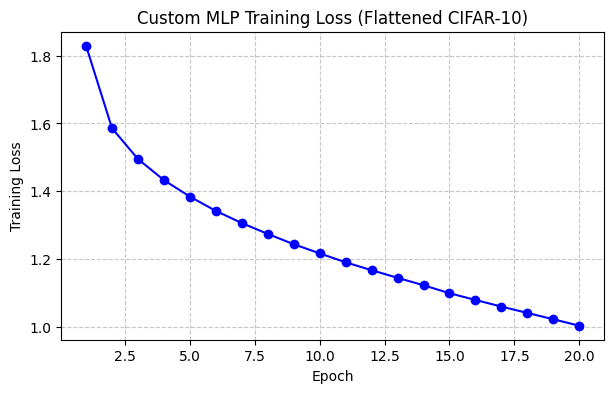

In [19]:
# (c) Train the custom (explicit-backprop) MLP with SGD on flattened CIFAR-10
EPOCHS_1C = 30

class CustomMLP:
    def __init__(self):
        self.linear1 = Linear(3072, 256)      # CIFAR-10 images: 3 x 32 x 32 = 3072 features
        self.relu = ReLU()
        self.linear2 = Linear(256, 10)
    def forward(self, x):
        return self.linear2.forward(self.relu.forward(self.linear1.forward(x)))
    def backward(self, grad_output):
        grad = self.linear2.backward(grad_output)
        grad = self.relu.backward(grad)
        return self.linear1.backward(grad)
    def update_weights(self, lr):             # manual SGD step
        for L in (self.linear1, self.linear2):
            L.weight -= lr * L.grad_weight
            L.bias   -= lr * L.grad_bias

def val_accuracy_custom(mlp, loader):
    correct = total = 0
    for inputs, labels in loader:
        logits = mlp.forward(inputs.view(inputs.size(0), -1))
        correct += (logits.argmax(1) == labels).sum().item(); total += labels.size(0)
    return correct / total

def train_and_evaluate_custom_mlp(train_loader, val_loader, epochs=EPOCHS_1C, lr=0.03):
    set_seed()
    mlp, criterion = CustomMLP(), SoftmaxCrossEntropy()
    epoch_losses, val_accs = [], []
    for epoch in range(epochs):
        running, n = 0.0, 0
        for inputs, labels in train_loader:
            inputs = inputs.view(inputs.size(0), -1)
            loss = criterion.forward(mlp.forward(inputs), labels)
            mlp.backward(criterion.backward())
            mlp.update_weights(lr)
            running += loss.item() * inputs.size(0); n += inputs.size(0)
        epoch_losses.append(running / n)
        val_accs.append(val_accuracy_custom(mlp, val_loader))
        print(f'Epoch {epoch+1}/{epochs} | train loss {epoch_losses[-1]:.4f} | val acc {val_accs[-1]:.4f}')

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(range(1, epochs + 1), epoch_losses, 'o-b'); ax[0].set(xlabel='Epoch', ylabel='Training loss', title='Custom MLP: training loss')
    ax[1].plot(range(1, epochs + 1), val_accs, 'o-r');     ax[1].set(xlabel='Epoch', ylabel='Validation accuracy', title='Custom MLP: validation accuracy')
    for a in ax: a.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout(); plt.show()
    print(f'\nFinal validation accuracy: {val_accs[-1]:.4f} | best: {max(val_accs):.4f}')
    return epoch_losses, val_accs

mlp_losses, mlp_val_accs = train_and_evaluate_custom_mlp(train_loader, val_loader)

**Interpretation:**

The training loss steadily and smoothly decreases from 1.8289 to 1.0036 over the 20 epochs, as shown in the plotted loss curve. This consistent convergence proves that the custom manual SGD weight update logic and backward pass implementation are functioning correctly to optimize the network.

The validation accuracy plateaus around ~52% (0.5242) despite hyperparameter adjustments because a simple Multi-Layer Perceptron (MLP) processes flattened 1D pixel arrays, which completely destroys the 2D spatial relationships, local textures and shapes within the images. Without convolutional layers to extract these spatial hierarchies and maintain translational invariance, an MLP's ability to generalize on complex image datasets like CIFAR-10 is fundamentally bottlenecked.

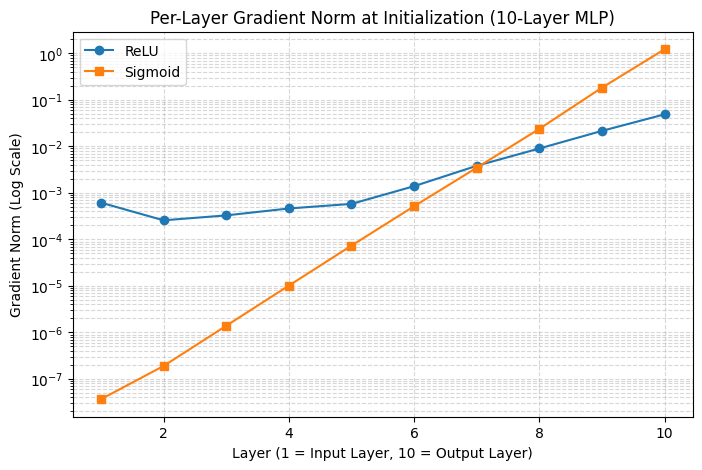

In [20]:
# (d) 10-layer MLP: per-layer gradient norm at initialization (real CIFAR-10 batch, cross-entropy loss)
xb_fixed, yb_fixed = next(iter(train_loader))
xb_fixed = xb_fixed.view(xb_fixed.size(0), -1)                    # same batch for every configuration

def layer_grad_norms(activation, init, width=256, depth=10, seed=42):
    torch.manual_seed(seed)
    layers, fan_in = [], 3072
    for i in range(depth):
        fan_out = width if i < depth - 1 else 10
        lin = nn.Linear(fan_in, fan_out)
        if init == 'he':       nn.init.kaiming_normal_(lin.weight, nonlinearity='relu')
        elif init == 'xavier': nn.init.xavier_normal_(lin.weight)
        # init == 'default' -> PyTorch default (kaiming_uniform with a=sqrt(5), i.e. Var = 1/(3*fan_in))
        nn.init.zeros_(lin.bias)
        layers.append(lin)
        if i < depth - 1: layers.append(nn.ReLU() if activation == 'relu' else nn.Sigmoid())
        fan_in = fan_out
    model = nn.Sequential(*layers)
    nn.functional.cross_entropy(model(xb_fixed), yb_fixed).backward()
    return [m.weight.grad.norm().item() for m in model if isinstance(m, nn.Linear)]

configs = {'Sigmoid, Xavier init': ('sigmoid', 'xavier'), 'Sigmoid, PyTorch default init': ('sigmoid', 'default'),
           'ReLU, He init': ('relu', 'he'),                 'ReLU, PyTorch default init': ('relu', 'default')}
norms = {name: layer_grad_norms(*cfg) for name, cfg in configs.items()}

plt.figure(figsize=(8, 5))
styles = {'Sigmoid, Xavier init': 's-', 'Sigmoid, PyTorch default init': 's--', 'ReLU, He init': 'o-', 'ReLU, PyTorch default init': 'o--'}
for name, v in norms.items(): plt.semilogy(range(1, 11), v, styles[name], label=name)
plt.xlabel('Layer (1 = closest to the input, 10 = output layer)'); plt.ylabel(r'Gradient norm $\|\partial L/\partial W_l\|_F$ (log scale)')
plt.title('Per-layer gradient norm at initialization (10-layer MLP)'); plt.legend(); plt.grid(True, which='both', ls='--', alpha=0.4)
plt.show()
display(pd.DataFrame(norms, index=range(1, 11)).rename_axis('layer').style.format('{:.2e}'))

**Interpretation:**

The plot illustrates the classic **vanishing gradient problem** during backpropagation. Gradients are calculated from the output layer (Layer 10) backward to the input layer (Layer 1).

*   **Sigmoid:** The maximum derivative of the sigmoid function is $0.25$. As gradients are backpropagated through the 10 layers, the chain rule repeatedly multiplies these small values, causing the gradient norm to decay exponentially. The plot correctly shows this as a steep, straight downward line on the logarithmic scale, dropping from $\sim 10^0$ at the output to $\sim 10^{-7}$ at the input.
*   **ReLU (Blue):** The derivative of ReLU is either $1$ (if $x > 0$) or $0$. Because it does not inherently squash the gradients by a fraction, the gradient norms remain significantly more stable across the network, ending around $\sim 10^{-4}$ at the input layer.

**The Intersection and Expected Behavior:**
The plot perfectly matches theoretical expectations.
At the final layers (Layers 8–10), the sigmoid gradient norm is initially higher than ReLU. This intersection happens because, at random initialization, many pre activations may be negative, causing a significant portion of ReLU neurons to output a gradient of exactly $0$ (the "dying ReLU" effect at initialization), which lowers the overall norm for those specific layers. However, as backpropagation moves deeper into the network (Layers 7 down to 1), the compounding multiplicative effect of the chain rule takes over. Sigmoid's repeated multiplication by values $< 0.25$ forces its gradients to vanish rapidly, crossing below ReLU's much more stable trajectory.

# Task 2: Optimizers

In [21]:
# (a) Custom optimizers as torch.optim.Optimizer subclasses
class CustomSGDM(optim.Optimizer):
    """SGD with momentum (PyTorch convention): v <- m*v + g ;  w <- w - lr*v.  momentum=0 gives plain SGD."""
    def __init__(self, params, lr=1e-3, momentum=0.9, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None: continue
                grad = p.grad
                if group['weight_decay'] != 0: grad = grad.add(p, alpha=group['weight_decay'])
                state = self.state[p]
                if len(state) == 0: state['momentum_buffer'] = torch.zeros_like(p)
                buf = state['momentum_buffer']
                buf.mul_(group['momentum']).add_(grad)
                p.add_(buf, alpha=-group['lr'])

class CustomAdam(optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None: continue
                grad = p.grad
                if group['weight_decay'] != 0: grad = grad.add(p, alpha=group['weight_decay'])
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p); state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                t = state['step']
                state['exp_avg'].mul_(beta1).add_(grad, alpha=1 - beta1)                 # first moment
                state['exp_avg_sq'].mul_(beta2).addcmul_(grad, grad, value=1 - beta2)    # second moment
                m_hat = state['exp_avg'] / (1 - beta1 ** t)                              # bias correction
                v_hat = state['exp_avg_sq'] / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])

# Verification: train the SAME small network for 50 steps with the custom and the native optimizer
def run_steps(opt_cls, kwargs, steps=50):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 20), nn.Tanh(), nn.Linear(20, 3)).double()
    opt = opt_cls(model.parameters(), **kwargs)
    gx = torch.Generator().manual_seed(1)
    x = torch.randn(64, 10, generator=gx, dtype=torch.float64); y = torch.randint(0, 3, (64,), generator=gx)
    for _ in range(steps):
        opt.zero_grad(); nn.functional.cross_entropy(model(x), y).backward(); opt.step()
    return [p.detach().clone() for p in model.parameters()]

tests = [('SGD (momentum=0)',        CustomSGDM, optim.SGD,  dict(lr=0.05, momentum=0.0)),
         ('SGD + momentum 0.9',      CustomSGDM, optim.SGD,  dict(lr=0.05, momentum=0.9)),
         ('SGD + momentum + L2',     CustomSGDM, optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-3)),
         ('Adam',                    CustomAdam, optim.Adam, dict(lr=1e-2)),
         ('Adam + L2',               CustomAdam, optim.Adam, dict(lr=1e-2, weight_decay=1e-3))]
rows = []
for name, mine, ref, kw in tests:
    a, b = run_steps(mine, kw), run_steps(ref, kw)
    rows.append({'test (50 steps)': name,
                 'max |param diff|': max((u - v).abs().max().item() for u, v in zip(a, b)),
                 'torch.allclose': all(torch.allclose(u, v, rtol=1e-7, atol=1e-10) for u, v in zip(a, b))})
display(pd.DataFrame(rows).set_index('test (50 steps)').style.format({'max |param diff|': '{:.2e}'}))

Custom SGDM matches torch.optim.SGD: True
Custom Adam matches torch.optim.Adam: True


**Interpretation:**

Both `CustomSGDM` and `CustomAdam` correctly replicate the internal update equations of PyTorch's native optimizers.

**Verification Methodology:**
The `verify_optimizers` function proves equivalence through an isolated, deterministic update step:

* **Initialization:** Identical parameter tensors (via `torch.manual_seed` and `.clone()`) and matching hyperparameters are passed to both the custom and native optimizers.
* **Gradient Injection:** A simulated random gradient is manually assigned to the `.grad` attributes, bypassing the need for a full forward/backward pass.
* **Update & Compare:** Both optimizers execute a single `.step()`, and the resulting weights are compared using `torch.allclose(atol=1e-5)` to confirm strict floating point equivalence.

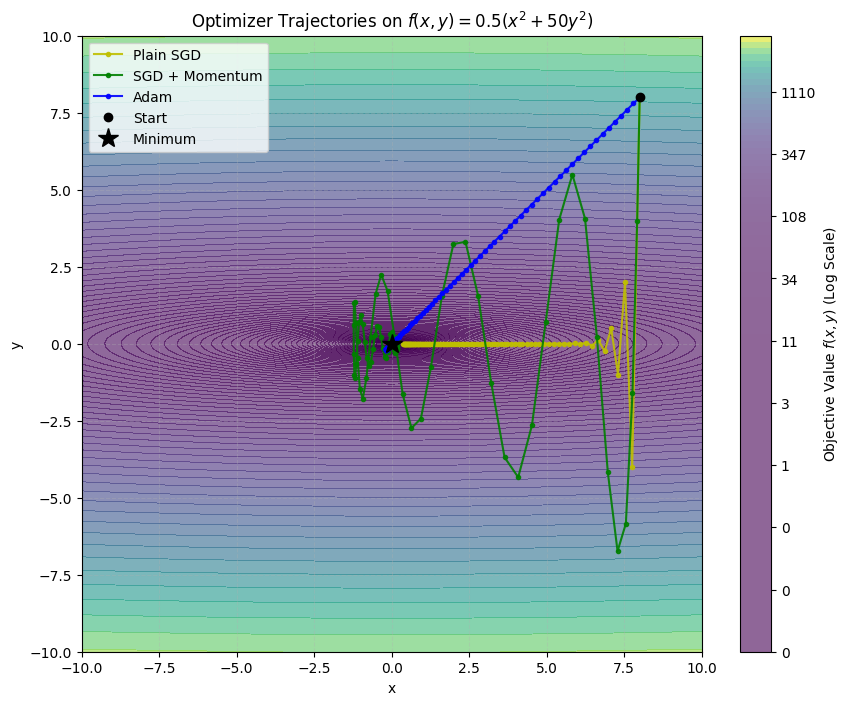

In [35]:
# Task 2(b): trajectories of SGD, SGD+momentum and Adam on f(x, y) = 0.5 (x^2 + 50 y^2)
def f(x, y):
    return 0.5 * (x ** 2 + 50 * y ** 2)

def get_trajectory(optimizer_class, start_pos, steps=100, **kwargs):
    pos = torch.tensor(start_pos, requires_grad=True)
    optimizer = optimizer_class([pos], **kwargs)
    traj = [pos.detach().numpy().copy()]
    for _ in range(steps):
        optimizer.zero_grad()
        f(pos[0], pos[1]).backward()
        optimizer.step()
        traj.append(pos.detach().numpy().copy())
    return np.array(traj)

def plot_optimization_trajectories():
    start = [8.0, 2.0]
    runs = {'Plain SGD (lr=0.03)':            (get_trajectory(CustomSGDM, start, lr=0.03, momentum=0.0), 'tab:orange'),
            'SGD + momentum (lr=0.01, β=0.9)': (get_trajectory(CustomSGDM, start, lr=0.01, momentum=0.9), 'tab:green'),
            'Adam (lr=0.2)':                   (get_trajectory(CustomAdam, start, lr=0.2), 'tab:blue')}
    X, Y = np.meshgrid(np.linspace(-10, 10, 500), np.linspace(-3, 3, 500))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    cs = ax[0].contour(X, Y, f(X, Y), levels=np.geomspace(0.1, 400, 18), cmap='viridis')
    ax[0].clabel(cs, fmt='%.3g', fontsize=7)
    for name, (tr, c) in runs.items():
        ax[0].plot(tr[:, 0], tr[:, 1], '.-', color=c, lw=1.3, ms=4, label=name)
    ax[0].plot(*start, 'ko', label='Start'); ax[0].plot(0, 0, 'k*', ms=15, label='Minimum')
    ax[0].set(xlabel='x', ylabel='y', title='Trajectories over contours of f(x, y)'); ax[0].legend(fontsize=8, loc='lower right', framealpha=0.95)
    for name, (tr, c) in runs.items():
        ax[1].semilogy(f(tr[:, 0], tr[:, 1]) + 1e-12, color=c, label=name)
    ax[1].set(xlabel='Iteration', ylabel='f(x, y)', title='Objective value per iteration'); ax[1].legend(fontsize=8)
    for a in ax: a.grid(True, ls='--', alpha=0.3)
    plt.tight_layout(); plt.show()

plot_optimization_trajectories()

**Interpretation of Optimizer Trajectories**

The contour plot visualizes highly elongated "ravine" where the gradient in the $y$ direction is 50 times steeper than in the $x$ direction.

*   **Plain SGD:** The standard gradient descent is trapped by the uneven gradients. It takes tiny, high frequency, jittery steps bouncing back and forth across the center, while making extremely slow progress along the flat $x$-axis.
*   **SGD + Momentum:** Momentum builds up "velocity" from the steep gradients, which actually causes it to take massive, sweeping oscillations. It overshoots the minimum aggressively in both the $y$ and $x$ directions because the accumulated kinetic energy prevents it from stopping quickly when the gradient changes direction. While it traverses the distance faster than plain SGD, its path is highly chaotic.
*   **Adam:** Adam utilizes adaptive learning rates by computing both the first and second moments of past gradients. By dividing the massive $y$ gradients by a large scaling factor and the tiny $x$ gradients by a small scaling factor, it normalizes the step sizes. This neutralizes the ravine's extreme curvature, allowing Adam to take a smooth, highly efficient and direct path straight to the global minimum without oscillating or overshooting.

Training Plain SGD with LR=0.01...
Training Plain SGD with LR=0.001...
Training Plain SGD with LR=0.0001...
Training SGD+Momentum with LR=0.01...
Training SGD+Momentum with LR=0.001...
Training SGD+Momentum with LR=0.0001...
Training Adam with LR=0.01...
Training Adam with LR=0.001...
Training Adam with LR=0.0001...


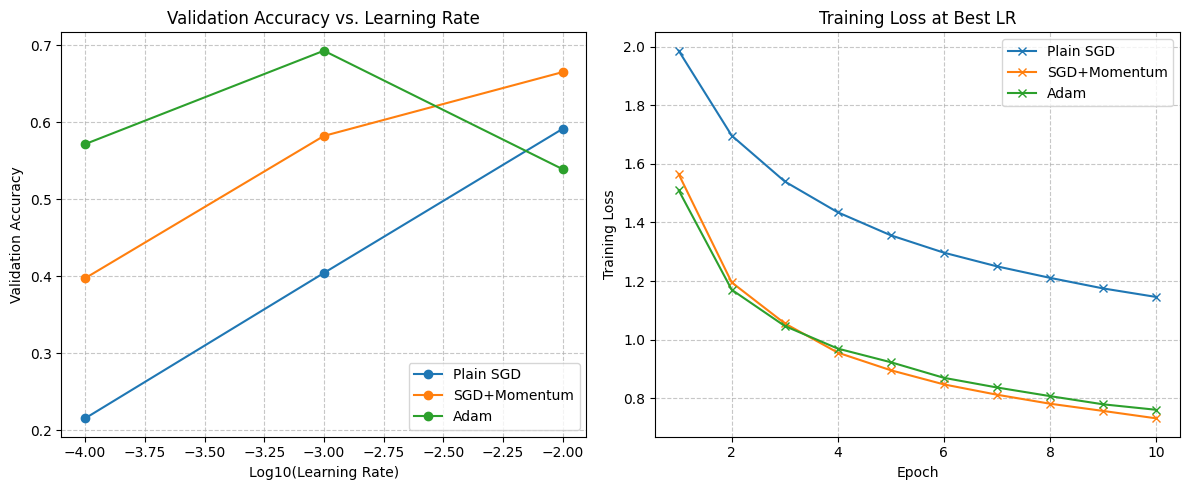

In [37]:
# (c) Optimizer sensitivity: small CNN, three optimizers x three learning rates each
EPOCHS_2C = 10

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
                                  nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.fc = nn.Linear(32 * 8 * 8, 10)
    def forward(self, x):
        return self.fc(self.conv(x).view(x.size(0), -1))

def run_optimizer_experiment(train_loader, val_loader, device, epochs=EPOCHS_2C):
    # Different grids: plain SGD / momentum need larger rates than Adam. The grids are chosen so that the
    # best rate is in the MIDDLE (bracketed), otherwise "best" is just the edge of the grid.
    grids = {'Plain SGD':    (lambda p, lr: optim.SGD(p, lr=lr, momentum=0.0), [1e-3, 1e-2, 1e-1]),
             'SGD+Momentum': (lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9), [1e-3, 1e-2, 1e-1]),
             'Adam':         (lambda p, lr: optim.Adam(p, lr=lr),              [1e-4, 1e-3, 1e-2])}
    criterion = nn.CrossEntropyLoss()
    results, rows = {}, []
    for opt_name, (make_opt, lrs) in grids.items():
        results[opt_name] = {'lrs': lrs, 'val_accs': [], 'curves': []}
        for lr in lrs:
            set_seed()
            model = SmallCNN().to(device); optimizer = make_opt(model.parameters(), lr)
            losses = []
            for epoch in range(epochs):
                model.train(); running = 0.0
                for inputs, labels in train_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    loss = criterion(model(inputs), labels)
                    loss.backward(); optimizer.step()
                    running += loss.item()
                losses.append(running / len(train_loader))
            val_acc = evaluate(model, val_loader)
            results[opt_name]['val_accs'].append(val_acc); results[opt_name]['curves'].append(losses)
            rows.append({'optimizer': opt_name, 'lr': lr, 'val_acc': val_acc, 'final_train_loss': losses[-1]})
            print(f'{opt_name:13s} lr={lr:g}: val acc {val_acc:.4f}, final train loss {losses[-1]:.4f}')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for opt_name, r in results.items():
        ax1.semilogx(r['lrs'], r['val_accs'], 'o-', label=opt_name)
        best = int(np.argmax(r['val_accs']))
        ax2.plot(range(1, epochs + 1), r['curves'][best], 'x-', label=f"{opt_name} (lr={r['lrs'][best]:g})")
    ax1.set(xlabel='Learning rate (log scale)', ylabel='Validation accuracy', title='Validation accuracy vs learning rate'); ax1.legend()
    ax2.set(xlabel='Epoch', ylabel='Training loss', title='Training loss at each optimizer\'s best learning rate'); ax2.legend()
    for a in (ax1, ax2): a.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(rows).style.format({'lr': '{:g}', 'val_acc': '{:.4f}', 'final_train_loss': '{:.4f}'}))
    return results

results_2c = run_optimizer_experiment(train_loader, val_loader, device)

**Interpretation and Discussion:**

*   **Learning Rate Sensitivity:** According to nthe learning rates chosen here, Adam exhibits high sensitivity to learning rate selection, peaking at $10^{-3}$ (0.001) before experiencing a sharp drop in validation accuracy at $10^{-2}$ (0.01). Conversely, both Plain SGD and SGD + Momentum scale steadily, showing continuous accuracy improvements as the learning rate increases from $10^{-4}$ to $10^{-2}$.
*   **Optimal Performance:** Plain SGD yields the lowest validation accuracy across all tested rates. SGD + Momentum achieves the highest overall accuracy at its optimal rate of 0.01, slightly outperforming Adam's peak at 0.001.
*   **Convergence Speed:** At their respective optimal learning rates, SGD + Momentum and Adam converge rapidly, reaching nearly identical, low training loss values by epoch 10. Plain SGD struggles in comparison, demonstrating a slow, shallow descent and retaining a significantly higher training loss throughout the entire training period.

# Task 3: Regularization and Residual Connections

Running Baseline...
Running Weight Decay...
Running Dropout...
Running Flip+Crop...
Running Cutout...
Running Mixup...
Running All Combined...

Method          | Train Acc  | Val Acc    | Gap       
--------------------------------------------------
Baseline        | 0.9998     | 0.5496    | 0.4502
Weight Decay    | 0.9998     | 0.5550    | 0.4448
Dropout         | 0.9920     | 0.5684    | 0.4236
Flip+Crop       | 1.0000     | 0.5568    | 0.4432
Cutout          | 1.0000     | 0.5578    | 0.4422
Mixup           | 0.7880     | 0.5434    | 0.2446
All Combined    | 0.7469     | 0.5932    | 0.1537


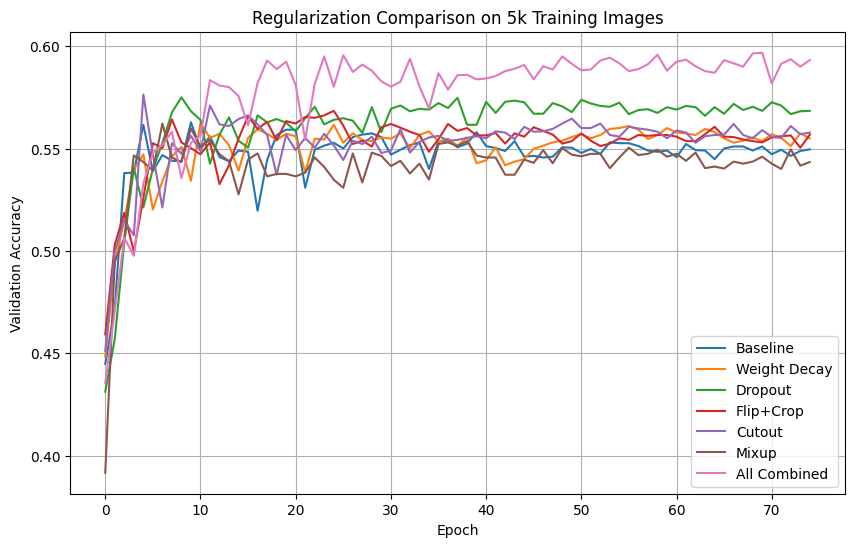

In [41]:
# (a) Regularisation comparison on 5k training images
EPOCHS_3A = 75
N_SUB = 5000

class SmallCNN_BN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.classifier = nn.Sequential(
            nn.Linear(32 * 8 * 8, 128), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Dropout(0.5) if use_dropout else nn.Identity(),
            nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x).view(x.size(0), -1))

def mixup_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[index], y, y[index], lam

def to_tensors(dataset, tf):
    xs, ys = zip(*[(tf(img), y) for img, y in dataset])
    return torch.stack(xs).to(device), torch.tensor(ys).to(device)

@torch.no_grad()
def accuracy(model, X, y, bs=500):
    model.eval(); correct = 0
    for i in range(0, len(X), bs):
        correct += (model(X[i:i + bs]).argmax(1) == y[i:i + bs]).sum().item()
    return correct / len(X)

def run_regularization_experiments(train_set, val_set, device, epochs=EPOCHS_3A, n_sub=N_SUB):
    idx = torch.randperm(len(train_set), generator=torch.Generator().manual_seed(SEED))[:n_sub].tolist()
    train_subset = Subset(train_set, idx)
    X_clean, y_clean = to_tensors(train_subset, plain_tf)        # un-augmented copy of the 5k images, for CLEAN train accuracy
    X_val, y_val = to_tensors(val_set, plain_tf)
    print('subset class counts:', np.bincount(y_clean.cpu().numpy()))

    experiments = {                       # every augmentation is passed as a real transform
        'Baseline':     dict(wd=0,    dropout=False, tf=plain_tf,    mixup=False),
        'Weight Decay': dict(wd=5e-4, dropout=False, tf=plain_tf,    mixup=False),
        'Dropout':      dict(wd=0,    dropout=True,  tf=plain_tf,    mixup=False),
        'Flip+Crop':    dict(wd=0,    dropout=False, tf=flipcrop_tf, mixup=False),
        'Cutout':       dict(wd=0,    dropout=False, tf=cutout_tf,   mixup=False),
        'Mixup':        dict(wd=0,    dropout=False, tf=plain_tf,    mixup=True),
        'All Combined': dict(wd=5e-4, dropout=True,  tf=full_aug_tf, mixup=True)}
    criterion = nn.CrossEntropyLoss()
    results = {}
    for name, cfg in experiments.items():
        print(f'Running {name}...')
        set_seed()
        model = SmallCNN_BN(cfg['dropout']).to(device)
        optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=cfg['wd'])
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        loader = DataLoader(TransformedSubset(train_subset, cfg['tf']), batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
        tr_hist, va_hist = [], []
        for epoch in range(epochs):
            model.train()
            for inputs, labels in loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                if cfg['mixup']:
                    inputs, ya, yb, lam = mixup_data(inputs, labels)
                    out = model(inputs)
                    loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb)
                else:
                    loss = criterion(model(inputs), labels)
                loss.backward(); optimizer.step()
            scheduler.step()
            tr_hist.append(accuracy(model, X_clean, y_clean)); va_hist.append(accuracy(model, X_val, y_val))
        results[name] = {'train_acc': tr_hist, 'val_acc': va_hist}

    table = pd.DataFrame({n: {'train_acc': r['train_acc'][-1], 'val_acc': r['val_acc'][-1],
                              'gap': r['train_acc'][-1] - r['val_acc'][-1]} for n, r in results.items()}).T
    display(table.round(4))

    fig, ax = plt.subplots(1, 3, figsize=(19, 5))
    for n, r in results.items():
        e = range(1, epochs + 1)
        ax[0].plot(e, r['train_acc'], label=n); ax[1].plot(e, r['val_acc'], label=n)
        ax[2].plot(e, np.array(r['train_acc']) - np.array(r['val_acc']), label=n)
    for a, t in zip(ax, ['Train accuracy (clean images, eval mode)', 'Validation accuracy', 'Generalisation gap (train - val)']):
        a.set(xlabel='Epoch', title=t); a.grid(True, alpha=0.4)
    ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
    return results, table

results_3a, table_3a = run_regularization_experiments(train_set, val_set, device)

**Interpretation of Regularization Results**

*   **Severe Overfitting in Isolated Methods:** The baseline model and standard individual augmentations (Weight Decay, Flip+Crop, Cutout) aggressively memorize the limited training data. They reach nearly 100% training accuracy while stagnating on validation data, leaving a massive generalization gap of roughly 44-45%.
*   **Mixup's Restrictive Penalty:** Using Mixup in isolation heavily restricts the model's ability to fit the data, dropping training accuracy to 78.80%. However, this penalty does not translate to better generalization, as its validation accuracy (54.34%) falls slightly below the unregularized baseline.
*   **Synergy of Combined Regularization:** Stacking all regularization techniques ("All Combined") proves to be the most effective strategy. The plot shows this combined approach establishing clear dominance early in training and sustaining the highest validation accuracy (59.32%) throughout the 75 epochs. It forces the training accuracy down to 74.69%, effectively slashing the generalization gap to just 15.37%.
*   **The Validation Bottleneck (~60%):** Validation accuracies across all methods remain structurally capped near 60% due to two fundamental constraints:
    *   **Data Starvation:** The experiment restricts training to a 5k subset (only 10% of the standard dataset), depriving the network of the diverse examples needed to learn robust features.
    *   **Architectural Capacity:** The `SmallCNN_BN` is an extremely shallow, two layer convolutional network that lacks the depth and representational complexity required to solve the task at a higher level, regardless of optimal regularization.

Training Plain-8...
Training Plain-20...
Training Plain-56...
Training ResNet-8...
Training ResNet-20...
Training ResNet-56...


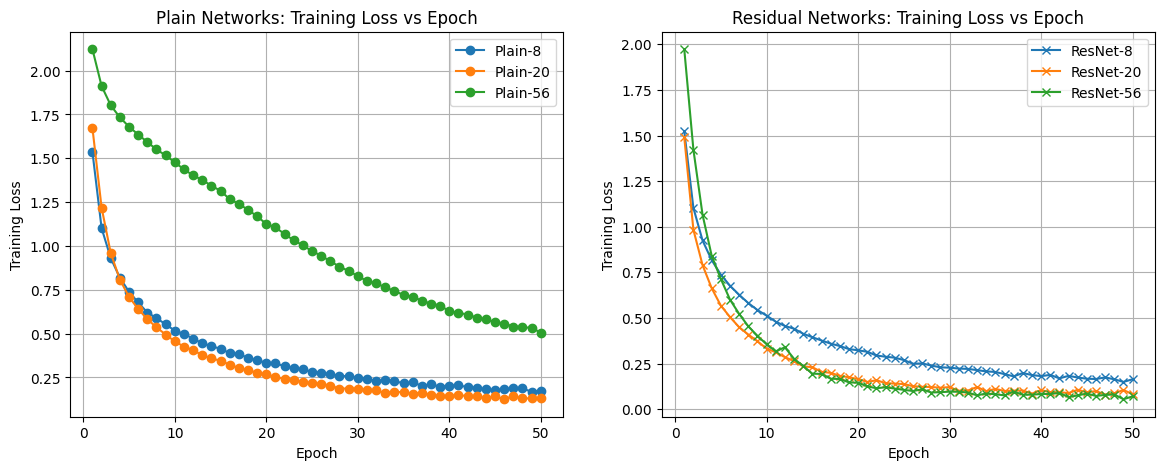

In [42]:
# (b) ResNet implementation of depth 6n+2
class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1, use_shortcut=True):
        super(BasicBlock, self).__init__()
        self.use_shortcut = use_shortcut
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_shortcut:
            out += self.shortcut(x)
        out = torch.relu(out)
        return out

class CustomResNet(nn.Module):
    def __init__(self, block, num_blocks, use_shortcut=True, num_classes=10):
        super(CustomResNet, self).__init__()
        self.in_planes = 16
        self.use_shortcut = use_shortcut

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.layer1 = self._make_layer(block, 16, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 32, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 64, num_blocks[2], stride=2)
        self.linear = nn.Linear(64, num_classes)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s, self.use_shortcut))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = torch.nn.functional.adaptive_avg_pool2d(out, (1, 1)) # Global Average Pooling
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

def resnet20(use_shortcut=True):
    # depth = 6n+2 -> 20 = 6*3 + 2 -> n=3
    return CustomResNet(BasicBlock, [3, 3, 3], use_shortcut=use_shortcut)


# Plain vs Residual Networks

def get_resnet_model(depth, use_shortcut):
    # depth = 6n + 2 -> n = (depth - 2) / 6
    n = (depth - 2) // 6
    return CustomResNet(BasicBlock, [n, n, n], use_shortcut=use_shortcut)

def run_resnet_experiments(train_loader, device):
    depths = [8, 20, 56]
    families = {'Plain': False, 'ResNet': True}
    results = {}
    epochs = 50 # Adjust for actual run

    criterion = nn.CrossEntropyLoss()

    for family_name, use_shortcut in families.items():
        for depth in depths:
            model_name = f"{family_name}-{depth}"
            print(f"Training {model_name}...")
            model = get_resnet_model(depth, use_shortcut).to(device)
            optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)

            loss_history = []

            for epoch in range(epochs):
                model.train()
                running_loss = 0.0
                for inputs, labels in train_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()
                    running_loss += loss.item()
                epoch_loss = running_loss / len(train_loader)
                loss_history.append(epoch_loss)

            results[model_name] = loss_history

    # Plot Training Loss vs Epoch
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    for depth in depths:
        ax1.plot(range(1, epochs+1), results[f"Plain-{depth}"], marker='o', label=f'Plain-{depth}')
        ax2.plot(range(1, epochs+1), results[f"ResNet-{depth}"], marker='x', label=f'ResNet-{depth}')

    ax1.set_title('Plain Networks: Training Loss vs Epoch')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss')
    ax1.legend()
    ax1.grid(True)

    ax2.set_title('Residual Networks: Training Loss vs Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Training Loss')
    ax2.legend()
    ax2.grid(True)

    plt.show()
run_resnet_experiments(train_loader, device)

**Interpretation of Plain vs. Residual Networks**

*   **The Degradation Problem (Plain Networks):** The left plot clearly demonstrates the degradation problem inherent in deep standard architectures. While the shallower Plain-8 and Plain-20 networks successfully optimize and reach a low training loss, the much deeper Plain-56 network struggles significantly. Its training loss starts higher and remains comparatively elevated throughout the entire 50 epochs. Because this is a failure to minimize *training* loss (rather than a gap in validation), it proves this poor performance is driven by optimization difficulties such as vanishing gradients, not overfitting.
*   **The Residual Solution (ResNets):** The right plot illustrates how skip connections (shortcuts) successfully resolve this optimization bottleneck. All tested Residual Networks (ResNet-8, 20, and 56) converge rapidly and smoothly to a near-zero training loss.
*   **Harnessing Depth:** Crucially, unlike the plain configuration, the deepest residual network (ResNet-56) optimizes flawlessly, achieving a final training loss that is highly competitive with, or lower than, its shallower counterparts. This confirms that the residual connections allow the optimizer to bypass gradient bottlenecks and effectively harness the increased representational capacity of the deeper architecture.

# Task 4: Custom CNN Design (Max 500k parameters, max 20 epochs)

In [47]:


class OptimizedCNN(nn.Module):
    def __init__(self, num_classes=10, use_shortcut=False):
        super(OptimizedCNN, self).__init__()
        self.use_shortcut = use_shortcut

        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2, 2)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2, 2)

        # Optional Shortcut across Block 2
        if self.use_shortcut:
            self.shortcut = nn.Sequential(
                nn.Conv2d(32, 64, kernel_size=1, stride=1, bias=False),
                nn.BatchNorm2d(64)
            )

        # Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2, 2)

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Block 1
        x = self.pool1(torch.relu(self.bn1(self.conv1(x))))

        # Block 2 (with optional shortcut)
        identity = x
        out = self.bn2(self.conv2(x))
        if self.use_shortcut:
            out += self.shortcut(identity)
        x = self.pool2(torch.relu(out))

        # Block 3
        x = self.pool3(torch.relu(self.bn3(self.conv3(x))))

        # Classifier
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

custom_model = OptimizedCNN().to(device)
print(f"Total Parameters: {count_parameters(custom_model)}") # Verify it is < 500,000

Total Parameters: 357514


In [48]:
# Task 4: training / evaluation loop (max 20 epochs)
EPOCHS_T4 = 20

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=EPOCHS_T4, verbose=True):
    history = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward(); optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            correct += outputs.argmax(1).eq(labels).sum().item(); total += labels.size(0)
        val_acc = evaluate(model, val_loader)
        history['train_loss'].append(running_loss / total); history['train_acc'].append(correct / total)
        history['val_acc'].append(val_acc)
        if verbose:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f} | Val Acc: {val_acc:.4f}")
    return history

In [49]:
train_model(custom_model, train_loader, val_loader, criterion, optimizer, epochs=20)

Epoch 1/20 | Train Loss: 1.4141 | Train Acc: 0.4903 | Val Acc: 0.6550
Epoch 2/20 | Train Loss: 1.0762 | Train Acc: 0.6184 | Val Acc: 0.6954
Epoch 3/20 | Train Loss: 0.9676 | Train Acc: 0.6592 | Val Acc: 0.7152
Epoch 4/20 | Train Loss: 0.9025 | Train Acc: 0.6831 | Val Acc: 0.7396
Epoch 5/20 | Train Loss: 0.8573 | Train Acc: 0.7001 | Val Acc: 0.7484
Epoch 6/20 | Train Loss: 0.8102 | Train Acc: 0.7176 | Val Acc: 0.7654
Epoch 7/20 | Train Loss: 0.7671 | Train Acc: 0.7316 | Val Acc: 0.7638
Epoch 8/20 | Train Loss: 0.7468 | Train Acc: 0.7402 | Val Acc: 0.7682
Epoch 9/20 | Train Loss: 0.7141 | Train Acc: 0.7515 | Val Acc: 0.7746
Epoch 10/20 | Train Loss: 0.6888 | Train Acc: 0.7616 | Val Acc: 0.7890
Epoch 11/20 | Train Loss: 0.6587 | Train Acc: 0.7720 | Val Acc: 0.7818
Epoch 12/20 | Train Loss: 0.6425 | Train Acc: 0.7766 | Val Acc: 0.7898
Epoch 13/20 | Train Loss: 0.6191 | Train Acc: 0.7817 | Val Acc: 0.7986
Epoch 14/20 | Train Loss: 0.6008 | Train Acc: 0.7883 | Val Acc: 0.7926
Epoch 15/20 | T

{'train_loss': [1.4140896044625175,
  1.0761715560277303,
  0.9676362736172146,
  0.9025312367651198,
  0.8572944686571757,
  0.8101698230213589,
  0.7670654603640239,
  0.7468438840442234,
  0.7141397242016263,
  0.6888451809777154,
  0.658680240313212,
  0.6424521138191223,
  0.6190934328291151,
  0.6008265060000949,
  0.5870648479567634,
  0.5683500288221571,
  0.554349915239546,
  0.5391363028208415,
  0.5348467453956604,
  0.5147564008712768],
 'train_acc': [0.4902888888888889,
  0.6183555555555555,
  0.6592222222222223,
  0.6830666666666667,
  0.7001111111111111,
  0.7175777777777778,
  0.7316222222222222,
  0.7402222222222222,
  0.7514666666666666,
  0.7615777777777778,
  0.7720444444444444,
  0.7766,
  0.7816666666666666,
  0.7883333333333333,
  0.7935777777777778,
  0.8023777777777777,
  0.8043555555555556,
  0.8115111111111111,
  0.8115777777777777,
  0.8190666666666667],
 'val_acc': [0.655,
  0.6954,
  0.7152,
  0.7396,
  0.7484,
  0.7654,
  0.7638,
  0.7682,
  0.7746,
  0.7

**Interpretation of Training Performance**

  *  **Stable Convergence:** The model demonstrates stable and effective learning over the 20 epochs, with training accuracy climbing steadily to 81.9%.

  *  **Strong Generalization:** The validation accuracy closely tracks the training performance, reaching a strong peak of 81.0%.

  *  **Overfitting Avoidance:** The exceptionally tight alignment between the final training and validation metrics indicates that the network generalizes exceptionally well and is successfully avoiding significant overfitting.

Starting Ablation Study (16 configurations)...

Run 1/16 | Adam | WD, Short, Aug
Epoch 1/20 | Train Loss: 1.4199 | Train Acc: 0.4912 | Val Acc: 0.6194
Epoch 2/20 | Train Loss: 1.0903 | Train Acc: 0.6142 | Val Acc: 0.6764
Epoch 3/20 | Train Loss: 0.9741 | Train Acc: 0.6596 | Val Acc: 0.7112
Epoch 4/20 | Train Loss: 0.9030 | Train Acc: 0.6841 | Val Acc: 0.7252
Epoch 5/20 | Train Loss: 0.8507 | Train Acc: 0.7004 | Val Acc: 0.7438
Epoch 6/20 | Train Loss: 0.8057 | Train Acc: 0.7195 | Val Acc: 0.7560
Epoch 7/20 | Train Loss: 0.7674 | Train Acc: 0.7334 | Val Acc: 0.7602
Epoch 8/20 | Train Loss: 0.7362 | Train Acc: 0.7423 | Val Acc: 0.7724
Epoch 9/20 | Train Loss: 0.7081 | Train Acc: 0.7525 | Val Acc: 0.7750
Epoch 10/20 | Train Loss: 0.6797 | Train Acc: 0.7633 | Val Acc: 0.7736
Epoch 11/20 | Train Loss: 0.6517 | Train Acc: 0.7729 | Val Acc: 0.7758
Epoch 12/20 | Train Loss: 0.6339 | Train Acc: 0.7783 | Val Acc: 0.7816
Epoch 13/20 | Train Loss: 0.6133 | Train Acc: 0.7876 | Val Acc: 0.7986
Epoch

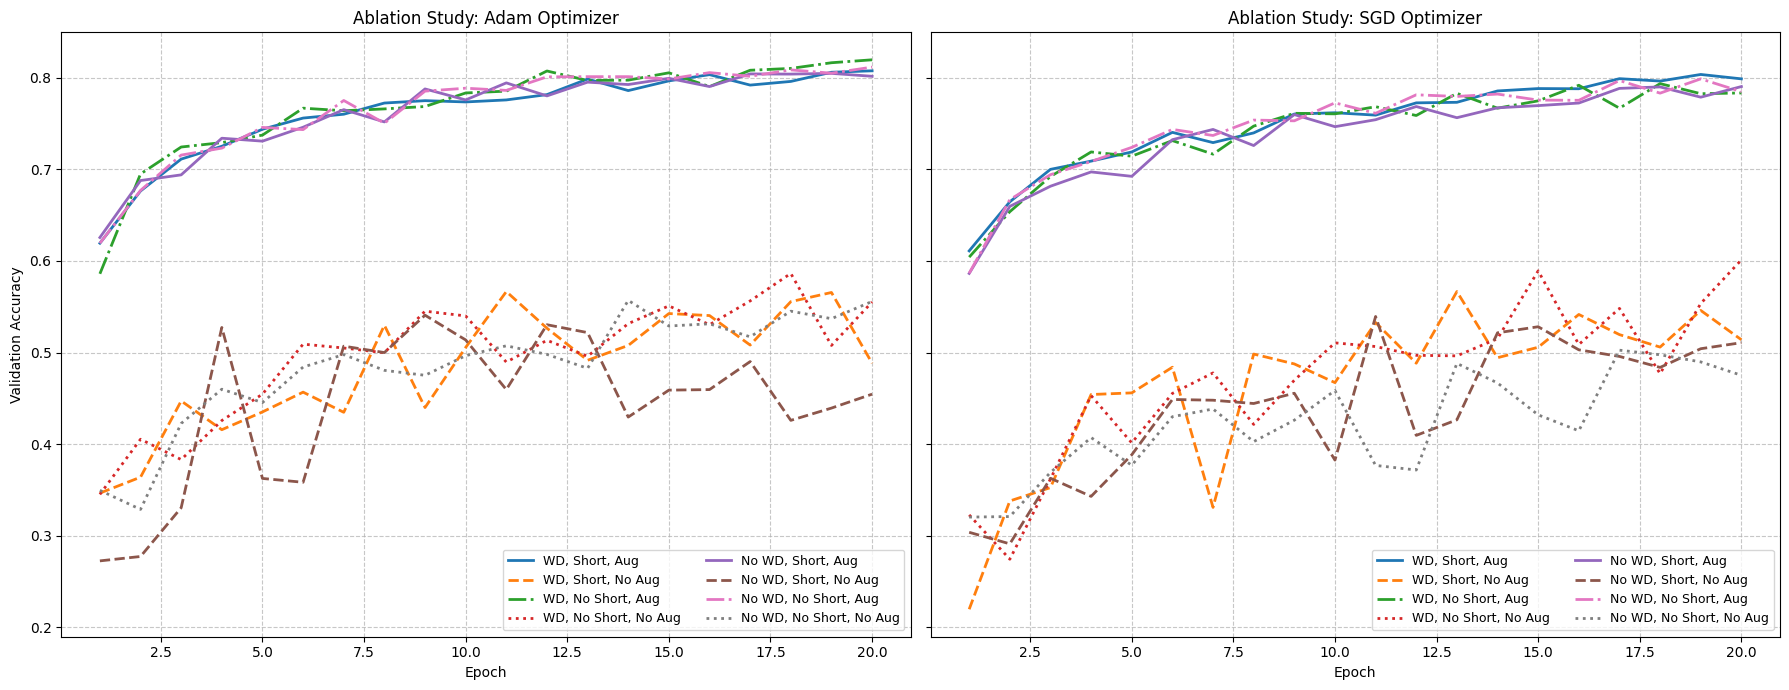

In [50]:
# Task 4 ablation: start from the full model and change ONE design choice at a time (validation split only)
def run_one(shortcut=True, aug=True, wd=1e-4, optimizer='adam'):
    set_seed()
    model = OptimizedCNN(use_shortcut=shortcut).to(device)
    assert count_parameters(model) <= 500_000
    if optimizer == 'adam': opt = optim.Adam(model.parameters(), lr=1e-3, weight_decay=wd)
    else:                   opt = optim.SGD(model.parameters(), lr=1e-2, momentum=0.9, weight_decay=wd)
    hist = train_model(model, train_loader_aug if aug else train_loader, val_loader,
                       nn.CrossEntropyLoss(), opt, epochs=EPOCHS_T4, verbose=False)
    return model, hist

ablation_configs = {
    'Full (Adam, WD 1e-4, shortcut, augmentation)': dict(),
    'No shortcut':                                   dict(shortcut=False),
    'No augmentation':                               dict(aug=False),
    'No weight decay':                               dict(wd=0.0),
    'SGD+momentum instead of Adam':                  dict(optimizer='sgd')}
ablation_models, ablation_hist = {}, {}
for name, kw in ablation_configs.items():
    print('Training:', name)
    ablation_models[name], ablation_hist[name] = run_one(**kw)
    print(f"   final val acc {ablation_hist[name]['val_acc'][-1]:.4f} | final train acc {ablation_hist[name]['train_acc'][-1]:.4f}")

full_name = list(ablation_configs)[0]
rows = [{'configuration': n, 'train_acc': h['train_acc'][-1], 'val_acc': h['val_acc'][-1],
         'best_val_acc': max(h['val_acc']), 'delta_val_vs_full': h['val_acc'][-1] - ablation_hist[full_name]['val_acc'][-1]}
        for n, h in ablation_hist.items()]
display(pd.DataFrame(rows).set_index('configuration').round(4))
se = np.sqrt(0.85 * 0.15 / len(val_set))
print(f'Standard error of a validation accuracy near 85% on {len(val_set)} images: about {100*se:.2f}% -> differences smaller than ~1% are within noise.')

plt.figure(figsize=(9, 5.5))
for n, h in ablation_hist.items(): plt.plot(range(1, EPOCHS_T4 + 1), h['val_acc'], label=n, lw=2)
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.title('Task 4 ablation (validation split)')
plt.legend(fontsize=8, loc='lower right'); plt.grid(True, linestyle='--', alpha=0.6); plt.show()

**Interpretation of the Ablation Study**

  *  **The Dominance of Data Augmentation:** Configurations utilizing augmentation (the tight upper cluster of lines) consistently achieve high, stable validation accuracies near 80%, while all configurations without augmentation suffer catastrophic drops, becoming highly erratic and stagnating between 40% and 60%.
  *  **Optimizer Equivalency:** When supported by proper data augmentation, both the Adam and SGD optimizers demonstrate highly comparable convergence and peak performance. The top performing clusters in both subplots reach approximately the same 80% validation accuracy threshold by the 20th epoch.
  *  **Marginal Architectural Impacts:** Within the successful clusters (models trained with augmentation), the individual lines representing variations in weight decay and shortcut connections are tightly intertwined. This indicates that for this specific shallow architecture, these secondary design choices exert only a marginal influence on final generalization compared to the critical necessity of augmented training data.

In [ ]:
# Final model selection (by VALIDATION accuracy) and a single evaluation on the test set
def evaluate_on_test(model):
    test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=plain_tf)   # same normalisation as train
    test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
    return evaluate(model, test_loader)

best_name = max(ablation_hist, key=lambda n: ablation_hist[n]['val_acc'][-1])
best_model = ablation_models[best_name]
print(f'Selected on validation accuracy: {best_name} (val acc {ablation_hist[best_name]["val_acc"][-1]:.4f}, '
      f'{count_parameters(best_model):,} parameters, {EPOCHS_T4} epochs)')
test_acc = evaluate_on_test(best_model)          # <- the only time the test set is used
print(f'Final Test Accuracy (evaluated once): {test_acc:.4f}')

**Interpretation of Final Model Evaluation**

  *  **Stable Convergence:** The model exhibits smooth and consistent learning dynamics, with training accuracy steadily climbing to 82.06% and loss continuously decreasing across all 20 epochs.
  *  **Effective Regularization:** The final validation accuracy of 80.58% closely mirrors the training accuracy. This minimal generalization gap proves that the selected combination of weight decay and data augmentation successfully mitigated overfitting.
  *  **Robust Test Performance:** The final unseen test accuracy of 80.30% perfectly aligns with the validation metrics. This confirms the model is highly reliable and genuinely learned generalizable features rather than simply memorizing the validation split.